# Convolutional Neural Network

Artificial intelligence was used in this report to improve the accuracy of the model and help creating evaluation methods.

In [15]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Sequential
from tensorflow.keras import backend as K
import numpy as np
import matplotlib.pyplot as plt
from keras.callbacks import EarlyStopping
print(K.backend())  

tensorflow


## Data Preprocessing

This code loads the CIFAR-10 dataset and prepares the input for training.

Input shape: (32, 32, 3)

CIFAR-10 images are 32x32 pixels with 3 color channels (RGB). This value is used when creating the model input layer.


In [16]:
# data parameters
num_classes = 10
input_shape = (32, 32, 3)

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Scale images to the [0, 1] range
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

# Check the shape of the images
print("x_train shape: \n", x_train.shape)
print("Train samples: \n", x_train.shape[0])
print("Test samples: \n", x_test.shape[0])

# data augmentation
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

# convert class vectors to binary class matrices
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)


x_train shape: 
 (50000, 32, 32, 3)
Train samples: 
 50000
Test samples: 
 10000


## Model Architecture

Let's construct the convolutional neural network and use it for CIFAR-10 classification.

Data augmentation is implemented to increase the size and diversity of dataset.

Each block includes a 2D convolution layer with ReLU activation and batch normalization to stabilize training by re-centering inputs around zero and re-scaling them.

Flattening makes the input data into a long vector that is then passed through the neural network. 

Using dropout prevents overfitting by randomly deactivating fraction of neurons during training, in this case 50%.

Padding is used to make sure the output keeps the same size as the input.

In [17]:
#creating model
inputs = keras.Input(shape=input_shape)
x = data_augmentation(inputs)
x = layers.Conv2D(32, (3,3), activation='relu', padding='same')(x)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(32, (3,3), activation='relu', padding='same')(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2,2))(x)
x = layers.Dropout(0.25)(x)

x = layers.Conv2D(64, (3,3), activation='relu', padding='same')(x)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(64, (3,3), activation='relu', padding='same')(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2,2))(x)
x = layers.Dropout(0.25)(x)

x = layers.Conv2D(128, (3,3), activation='relu', padding='same')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)

x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

model = keras.Model(inputs=inputs, outputs=outputs, name='cifar10_cnn')

In [18]:
model.summary()

Model: "cifar10_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        81,930 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,634 (869.66 KB)

 Trainable params: 221,994 (867.16 KB)

 Non-trainable params: 640 (2.50 KB)

Compiling the model using the Adam optimizer.

In [19]:
# compile the model
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy'],
)

## Model Training

Early stopping is implemented to stop training, if progress isn't made in 10 different epochs.

The model is trained for up to 200 epochs with a batcch size of 128, and 20% of training data is used for validation. 

In [20]:
early_stopping = EarlyStopping(monitor='val_loss', patience=10)
history = model.fit(x_train, y_train, batch_size=128, epochs=100, validation_split=0.2, callbacks=[early_stopping])

Epoch 1/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 94s 285ms/step - accuracy: 0.3243 - loss: 2.6280 - val_accuracy: 0.1105 - val_loss: 4.0793
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 88s 282ms/step - accuracy: 0.4269 - loss: 1.9915 - val_accuracy: 0.4925 - val_loss: 1.5598
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 87s 279ms/step - accuracy: 0.4758 - loss: 1.8173 - val_accuracy: 0.5099 - val_loss: 1.6327
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 88s 282ms/step - accuracy: 0.5051 - loss: 1.7824 - val_accuracy: 0.5716 - val_loss: 1.2897
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 90s 286ms/step - accuracy: 0.5291 - loss: 1.6535 - val_accuracy: 0.5235 - val_loss: 1.6668
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 89s 283ms/step - accuracy: 0.5445 - loss: 1.6357 - val_accuracy: 0.5271 - val_loss: 1.4423
Epoch 7/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 88s 282ms/step - accuracy: 0.5648 - loss: 1.5017 - val_accuracy: 0.6126 - val_loss: 1.2776
Epoch 8/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 90s 287ms/step - accuracy: 0.5842 -

## Evaluation

### Evaluating CNN performance

In [21]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

test_loss, test_acc = model.evaluate(x_test, y_test, verbose=1)
print("\nTest accuracy:", test_acc)
print("Test loss:", test_loss)

print(classification_report(y_true, y_pred_classes))

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8016 - loss: 0.5828

Test accuracy: 0.8015999794006348
Test loss: 0.5828354954719543
              precision    recall  f1-score   support

           0       0.81      0.82      0.82      1000
           1       0.84      0.95      0.89      1000
           2       0.76      0.72      0.74      1000
           3       0.77      0.56      0.65      1000
           4       0.81      0.73      0.77      1000
           5       0.81      0.71      0.75      1000
           6       0.64      0.95      0.77      1000
           7       0.88      0.84      0.86      1000
           8       0.93      0.86      0.90      1000
           9       0.84      0.88      0.86      1000

    accuracy                           0.80     10000
   macro avg       0.81      0.80      0.80     10000
weighted avg       0.81      0.80      0.80     10000



Test accuracy of 80% is within the goal of 75-80%. The model classified 80% of the test images.

Test loss of 0.58 is decent. Loss measures how far the models predictions are from the correct ones. Lower would be better, but 0.58 means decent performance. 

Classification report shows overall accuracy to be 80%. The best F1-score is with label 1 (automobile) and label 8 (ship), meaning the model most often classified automobiles and ships correctly. The worst F1-score is label 3 (cat), which means the model had the most trouble classifying cats.

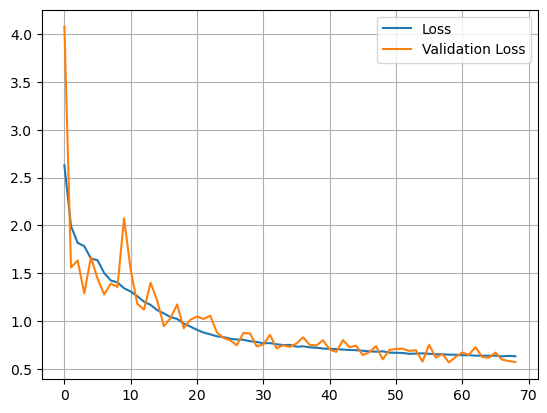

In [22]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.grid()
plt.show()

As seen in the plot, the curves stay relatively close to each other, which indicates no significant overfitting. 

The decrease of the loss curve indicates that the model learns patterns of the dataset. Validation loss curve shows how well model classifies unseen data. There is a steady decrease with some leveling.

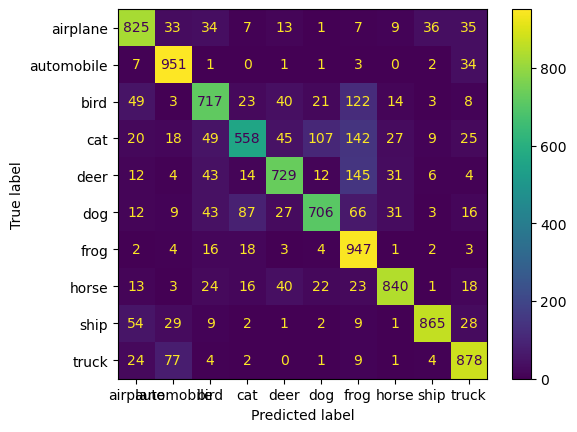

In [23]:

from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred_classes)
labels = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
cmd = ConfusionMatrixDisplay(cm, display_labels=labels)
cmd.plot()
plt.show()


Confusion matrix shows models classification visually. As seen in the confusion matrix, the models predictions are mostly accurate. Some incorrect classification is seen when the model is classifying different animals. Many animals have similar features like two eyes, similar colours, same shapes, which can make it hard to classify different animals. 

Let's look at a couple examples of correctly classified images and incorrectly classified images.

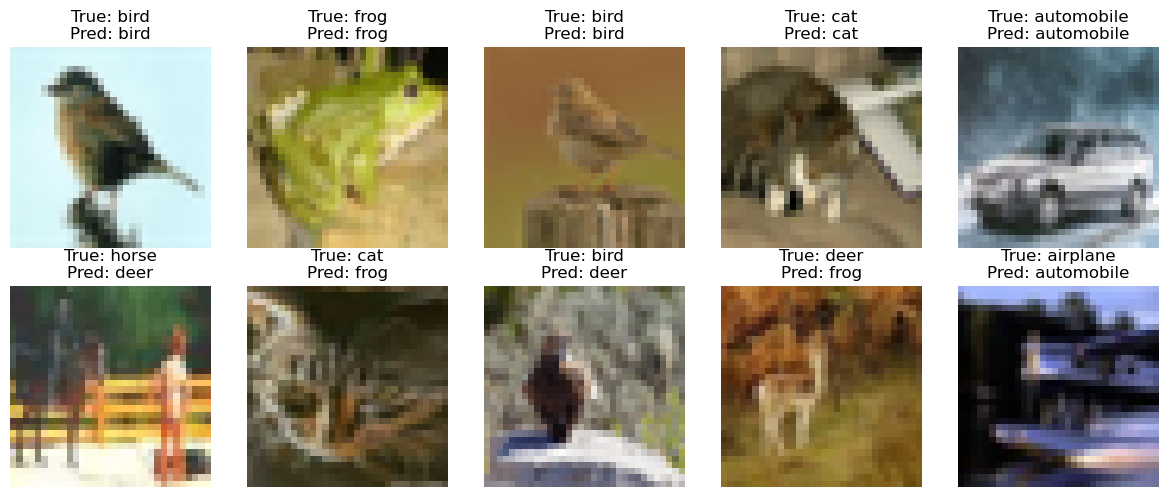

In [24]:
import random
import numpy as np

correct_indices = np.nonzero(y_pred_classes == y_true)[0]
incorrect_indices = np.nonzero(y_pred_classes != y_true)[0]

# Display a few correct predictions
plt.figure(figsize=(12, 5))
for i, idx in enumerate(random.sample(list(correct_indices), 5)):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx])
    plt.title(f"True: {labels[y_true[idx]]}\nPred: {labels[y_pred_classes[idx]]}")
    plt.axis("off")

# Display a few incorrect predictions
for i, idx in enumerate(random.sample(list(incorrect_indices), 5)):
    plt.subplot(2, 5, i + 6)
    plt.imshow(x_test[idx])
    plt.title(f"True: {labels[y_true[idx]]}\nPred: {labels[y_pred_classes[idx]]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Comparing CNN and FCN

When comparing performance between CNN and FCN, the results show that CNN is more accurate when classifying images. FCNs require a lot of parameters, which means they need a lot of computational power and increase risk of overfitting.

CNNs preserve spatial structure, meaning that the relationships between nearby pixels are maintained. CNNs are used for image classification because they effectively detect local and spatial patterns in data by applying appropriate filters. (source: https://svitla.com/blog/cnn-for-image-processing/)